In [1]:
	# import libraries
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

In [2]:
	# create a function to display model fitting

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # create a grid for model evaluation
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot boundary and margins
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

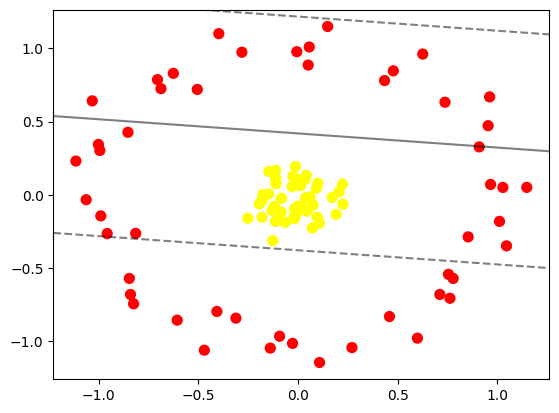

In [3]:
	# example of non-linearly separable data
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [4]:
r = np.exp(-(X**2).sum(1))

In [5]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

	interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
	         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.04605713e+00, -3.48959488e-01],
       [ 1.48439483e-01,  1.14876584e+00],
       [-2.77333310e-02, -1.01491757e+00],
       [-1.47861113e-01,  4.88315199e-03],
       [-8.25520203e-01, -7.44844117e-01],
       [-3.12121434e-01, -8.42357859e-01],
       [-9.25383677e-02, -1.67407907e-01],
       [-1.30040561e-01, -1.06475284e-01],
       [-5.05994810e-01,  7.18844634e-01],
       [-2.10217865e-03, -7.84252192e-02],
       [-9.90124218e-01, -1.44433811e-01],
       [-6.26049749e-01,  8.28820056e-01],
       [-6.88131904e-01,  7.24133417e-01],
       [ 9.67032247e-02, -1.53987516e-01],
       [-6.34901134e-03,  9.76583772e-01],
       [-1.11122221e-01,  7.53913617e-02],
       [-1.21128791e-01, -8.19544348e-02],
       [-6.06755706e-01, -8.56421311e-01],
       [-2.62552408e-02,  1.26031003e-01],
       [ 7.62460506e-01, -7.06633121e-01],
       [-8.41032622e-01, -6.81008802e-01],
       [-2.52593250e-01, -1.60032698e-01],
       [-1.78084572e-02, -9.54547546e-02],
       [-1.26992872e-01, -3.13552165e-01],
       [-1.33065145e-02,  1.92842585e-01],
       [ 1.71347899e-01, -1.82285420e-02],
       [-4.70587548e-01, -1.06120425e+00],
       [-9.94884911e-01,  3.02089885e-01],
       [ 9.08909325e-01,  3.26707146e-01],
       [-7.05719461e-01,  7.85805893e-01],
       [ 1.25857647e-02,  6.24447611e-02],
       [ 1.73628931e-02, -7.71621041e-02],
       [-1.11518935e+00,  2.30125464e-01],
       [-1.39675866e-01, -1.04715119e+00],
       [-3.97819616e-01,  1.09969305e+00],
       [ 4.78001365e-01,  8.45953392e-01],
       [-8.47029297e-01, -5.71495440e-01],
       [ 5.60828644e-02,  1.00874620e+00],
       [ 7.49151792e-02, -7.09284222e-02],
       [-6.54193430e-02, -1.88410866e-01],
       [-9.29147368e-02, -9.65924272e-01],
       [-1.80572671e-01, -1.53425140e-01],
       [-2.02255001e-02, -1.53424622e-01],
       [-1.66995498e-02,  7.05231895e-02],
       [-1.49671059e-02, -1.39280837e-01],
       [-1.19291355e-01, -7.97298053e-02],
       [-9.58228376e-01, -2.64953236e-01],
       [-1.76930312e-01,  5.88445180e-04],
       [ 8.64266684e-03,  1.01051972e-01],
       [-1.47155115e-01,  1.59302988e-01],
       [-1.94786854e-01, -6.24805037e-02],
       [ 4.58587261e-01, -8.31386876e-01],
       [-8.51808208e-02, -1.18385585e-01],
       [ 3.57523898e-02,  1.06780221e-01],
       [ 1.06343152e-01, -1.95081262e-01],
       [ 9.61350132e-01,  6.68070263e-01],
       [-8.15012963e-01, -2.63588554e-01],
       [-1.80853558e-01, -3.90483964e-02],
       [-2.98650548e-02,  5.58594146e-02],
       [ 2.70285604e-01, -1.04351895e+00],
       [ 9.66205523e-01,  7.01349207e-02],
       [ 9.53854390e-01,  4.71387204e-01],
       [ 7.37292392e-01,  6.31673619e-01],
       [ 5.07617699e-02,  8.85368888e-01],
       [-8.27752115e-02, -2.39261329e-02],
       [-1.03304185e+00,  6.40918671e-01],
       [-1.12579138e-01,  1.12305834e-01],
       [ 1.14792703e+00,  5.03594452e-02],
       [ 9.19718556e-02,  4.61658733e-02],
       [ 1.22406655e-02, -9.52745593e-02],
       [-1.87799692e-02, -1.62870116e-01],
       [ 6.25730051e-01,  9.60542981e-01],
       [ 7.78398019e-01, -5.71567603e-01],
       [-1.13676703e-01, -1.82064841e-01],
       [ 7.54726664e-01, -5.43278559e-01],
       [ 9.94489407e-02,  7.85185351e-02],
       [ 8.82523706e-04, -1.12334788e-01],
       [ 1.90662266e-01, -1.34234218e-01],
       [ 8.53629060e-01, -2.87612034e-01],
       [ 5.94304251e-02, -1.43753819e-02],
       [ 7.11412831e-01, -6.80506215e-01],
       [ 1.07727562e-01, -1.14514981e+00],
       [ 4.56139527e-02, -1.12594378e-01],
       [ 5.11171756e-03,  1.01583646e-01],
       [-1.00220538e+00,  3.43130882e-01],
       [ 2.06406417e-01,  2.15693781e-02],
       [ 1.02797486e+00,  5.01613541e-02],
       [ 3.74554491e-02, -2.13675447e-02],
       [ 2.23444092e-01,  7.25919132e-02],
       [-1.13006642e-01,  1.67137181e-01],
       [ 4.33956659e-01,  7.79500335e-01],
       [ 1.01090866e+00, -1.81828668e-01

In [6]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

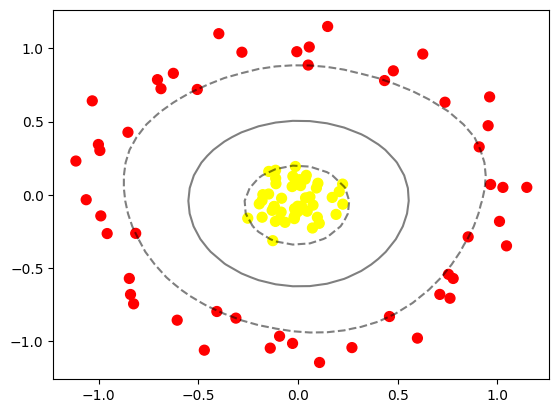

In [7]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')